# Step 1: Getting to know the data

Goal: before cleaning or modelling anything, understand what one row means,
what we are predicting, and what is broken or strange in the data.

In [15]:
import pandas as pd

pd.set_option("display.max_columns", 60)

df = pd.read_csv("../data/diabetic_data.csv")
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. What is one row?

Each row is **one hospital visit** (an *encounter*), not one patient.
`encounter_id` is unique per visit, `patient_nbr` identifies the patient.

In [16]:
print("visits:  ", df["encounter_id"].nunique())
print("patients:", df["patient_nbr"].nunique())

visits_per_patient = df.groupby("patient_nbr").size()
visits_per_patient.value_counts().sort_index().head(10)

visits:   101766
patients: 71518


1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: count, dtype: int64

## 2. What are we predicting?

`readmitted` has three values:
- `NO`: not readmitted
- `>30`: readmitted after more than 30 days
- `<30`: readmitted within 30 days, **this is our positive class**

In [17]:
df["readmitted"].value_counts(normalize=True).round(3)

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64

## 3. Hidden missing values

This dataset does not use empty cells for missing values. It uses the text `"?"`,
so pandas thinks those cells have a value. We have to count them ourselves.

In [18]:
question_marks = (df == "?").sum()
question_marks = question_marks[question_marks > 0].sort_values(ascending=False)

pd.DataFrame({
    "count": question_marks,
    "percent": (question_marks / len(df) * 100).round(1),
})

,count,percent
weight,98569,96.9
medical_specialty,49949,49.1
payer_code,40256,39.6
race,2273,2.2
diag_3,1423,1.4
diag_2,358,0.4
diag_1,21,0.0


## 4. Patients who cannot be readmitted

`discharge_disposition_id` says where the patient went after the visit.
The meaning of each id is in `IDS_mapping.csv`. Some patients died or went to
hospice care. They can never be readmitted, so they would teach the model
something false.

In [19]:
def read_mapping(section):
    """IDS_mapping.csv has three small tables one after another, separated by
    empty lines. Return the one whose first column is `section` as a dict."""
    tables = open("../data/IDS_mapping.csv").read().strip().split("\n,\n")
    for table in tables:
        lines = table.strip().splitlines()
        if lines[0].startswith(section):
            return {int(line.split(",", 1)[0]): line.split(",", 1)[1].strip('"')
                    for line in lines[1:] if line.split(",", 1)[0].strip()}

discharge = read_mapping("discharge_disposition_id")

counts = df["discharge_disposition_id"].value_counts()
pd.DataFrame({"meaning": counts.index.map(discharge), "visits": counts.values},
             index=counts.index).head(15)

,meaning,visits
discharge_disposition_id,,
1,Discharged to home,60234
3,Discharged/transferred to SNF,13954
6,Discharged/transferred to home with home healt...,12902
18,NULL,3691
2,Discharged/transferred to another short term h...,2128
22,Discharged/transferred to another rehab fac in...,1993
11,Expired,1642
5,Discharged/transferred to another type of inpa...,1184
25,Not Mapped,989


## 5. Diagnosis codes

`diag_1`, `diag_2`, `diag_3` are ICD-9 codes: the main diagnosis and two secondary ones.
Codes are text: mostly numbers like `250.83` (diabetes) or `428` (heart failure),
but some start with `V` or `E`.

In [20]:
print(df[["diag_1", "diag_2", "diag_3"]].nunique())
df["diag_1"].value_counts().head(10)

diag_1    717
diag_2    749
diag_3    790
dtype: int64


diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

In [21]:
df.loc[df["diag_1"].str.startswith(("V", "E")), "diag_1"].value_counts().head(5)

diag_1
V57    1207
V58     228
V55      71
V54      45
V53      44
Name: count, dtype: int64

## 6. Numeric columns

In [22]:
numeric = ["time_in_hospital", "num_lab_procedures", "num_procedures",
           "num_medications", "number_outpatient", "number_emergency",
           "number_inpatient", "number_diagnoses"]
df[numeric].describe().round(1)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.0,101766.0,101766.0,101766.0,101766.0,101766.0,101766.0,101766.0
mean,4.4,43.1,1.3,16.0,0.4,0.2,0.6,7.4
std,3.0,19.7,1.7,8.1,1.3,0.9,1.3,1.9
min,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
25%,2.0,31.0,0.0,10.0,0.0,0.0,0.0,6.0
50%,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0
75%,6.0,57.0,2.0,20.0,0.0,0.0,1.0,9.0
max,14.0,132.0,6.0,81.0,42.0,76.0,21.0,16.0


## 7. Columns that almost never change

There are 23 medication columns. Some of them have the same value in almost every
row. A column like that cannot help the model tell patients apart.

In [23]:
top_share = {col: df[col].value_counts(normalize=True).iloc[0] for col in df.columns}
top_share = pd.Series(top_share).sort_values(ascending=False)
(top_share[top_share > 0.99] * 100).round(2)

citoglipton                 100.00
examide                     100.00
metformin-pioglitazone      100.00
acetohexamide               100.00
glimepiride-pioglitazone    100.00
metformin-rosiglitazone     100.00
troglitazone                100.00
glipizide-metformin          99.99
tolbutamide                  99.98
miglitol                     99.96
tolazamide                   99.96
chlorpropamide               99.92
acarbose                     99.70
nateglinide                  99.31
glyburide-metformin          99.31
dtype: float64

## 8. A first look at what matters

Readmission rate within 30 days, by number of inpatient visits in the year before.

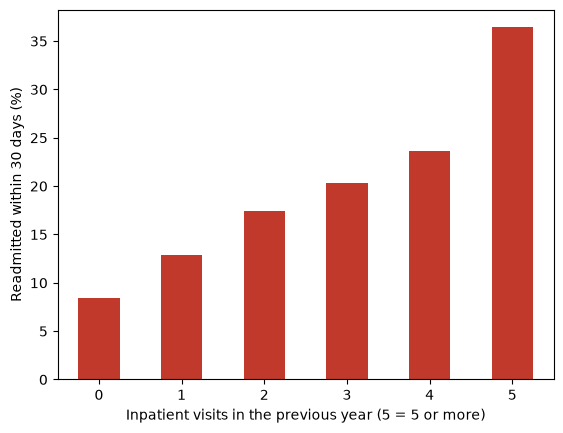

In [24]:
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

rate = df.groupby(df["number_inpatient"].clip(upper=5))["readmitted_30"].mean()
ax = (rate * 100).plot.bar(color="#c0392b", rot=0)
ax.set_xlabel("Inpatient visits in the previous year (5 = 5 or more)")
ax.set_ylabel("Readmitted within 30 days (%)");

## Findings

1. **One row is one hospital visit, not one patient.** 101,766 visits come from
   71,518 patients, and about 23% of patients appear more than once. When splitting
   into train and test, all visits of a patient must stay on the same side.
2. **The target is imbalanced.** Only 11.2% of visits are readmitted within 30 days.
   A model that always predicts "no" would get 88.8% accuracy while finding no one,
   so accuracy is not a useful metric here.
3. **Missing values are written as `?`.** `weight` is 97% missing and `payer_code`
   40%: both will be dropped. `medical_specialty` (49%) and `race` (2%) are kept,
   with missing values as their own "Unknown" category.
4. **Some visits cannot lead to a readmission.** Patients who died or were sent to
   hospice must be removed, otherwise the model learns from cases where readmission
   was impossible.
5. **Diagnoses have around 700 different ICD-9 codes**, including codes starting
   with `V` and `E`. They need to be grouped into a small number of categories.
6. **Some medication columns are constant** (e.g. `examide`, `citoglipton`) and
   carry no information. They will be dropped.
7. **Past inpatient visits are a strong signal.** The 30-day readmission rate rises
   from 8% for patients with no inpatient visit in the previous year to 36% for
   those with five or more.